# FIRE Fine-Tuning on OpenFake


## Cell 1 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
ZIP_PATH = '/content/drive/MyDrive/Adv_CV_Project/openfake_subset.zip'
assert os.path.exists(ZIP_PATH), f'Zip not found at {ZIP_PATH}'
print(f'Found zip: {ZIP_PATH}')

Mounted at /content/drive
Found zip: /content/drive/MyDrive/Adv_CV_Project/openfake_subset.zip


## Cell 1-B — Session Keepalive

Runs a background thread that pings the Colab kernel every 60 s to prevent
idle-timeout disconnections during multi-hour training.


In [ ]:
# ── Colab session keepalive ───────────────────────────────────────────────────
# Prevents Colab from disconnecting the runtime due to inactivity during long
# training runs. Runs in a daemon thread — dies automatically when the kernel stops.
import threading, time

def _keepalive_loop(interval_s=55):
    """Sends a no-op JS call every `interval_s` seconds to prevent idle timeout."""
    try:
        from google.colab import output
        while True:
            time.sleep(interval_s)
            try:
                # Touch the DOM to signal activity to Colab
                output.eval_js('''
                    (() => {
                        const btn = document.querySelector("colab-connect-button");
                        if (btn) { btn.click(); }
                        // Also touch the kernel heartbeat path
                        if (window._handleMessageEvent) { window._handleMessageEvent({}); }
                    })();
                ''', ignore_result=True)
            except Exception:
                pass  # JS call failed — non-fatal, keep looping
    except ImportError:
        pass  # Not in Colab — silently no-op

_ka_thread = threading.Thread(target=_keepalive_loop, daemon=True)
_ka_thread.start()
print(f'Session keepalive started (ping every 55 s). This thread will keep '
      f'the Colab session alive during training.')


Session keepalive started (ping every 55 s). This thread will keep the Colab session alive during training.


## Cell 2 — Extract Dataset

In [ ]:
import zipfile, os

EXTRACT_DIR = '/content/dataset'
os.makedirs(EXTRACT_DIR, exist_ok=True)

print('Extracting zip (this may take a few minutes)...')
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
print('Done.')

for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, '').count(os.sep)
    if depth > 2:
        continue
    indent = '  ' * depth
    print(f'{indent}{os.path.basename(root)}/')
    if depth == 2:
        print(f'{indent}  ... ({len(files)} files)')

Extracting zip (this may take a few minutes)...
Done.
dataset/
  images/


## Cell 3 — Load Metadata and Fix Paths

In [ ]:
import pandas as pd

METADATA_PATH = '/content/dataset/metadata.csv'
df = pd.read_csv(METADATA_PATH)

df['image_path'] = df['image_path'].str.replace(
    '/content/openfake_subset/images',
    '/content/dataset/images',
    regex=False
)

sample = df['image_path'].iloc[0]
print(f'Remapped path sample : {sample}')
print(f'File exists          : {os.path.exists(sample)}')
print(f'\nShape: {df.shape}')
print(f'\nLabels:\n{df["label"].value_counts()}')

Remapped path sample : /content/dataset/images/0.jpg
File exists          : True

Shape: (8989, 4)

Labels:
label
real                3000
stable_diffusion    3000
midjourney          2989
Name: count, dtype: int64


## Cell 4 — Create Train / Val / Test Splits


In [ ]:
import pandas as pd, os, shutil

METADATA_PATH = '/content/dataset/metadata.csv'
OUT_BASE      = '/content/splits'

df = pd.read_csv(METADATA_PATH)

df['image_path'] = df['image_path'].str.replace(
    '/content/openfake_subset/images',
    '/content/dataset/images', regex=False
)


sample = df['image_path'].iloc[0]
print(f'Remapped path sample : {sample}')
print(f'File exists          : {os.path.exists(sample)}')

df['split_label'] = df['label'].apply(lambda x: 'real' if str(x).lower() == 'real' else 'fake')

real_df = df[df['split_label'] == 'real'].copy()
fake_df = df[df['split_label'] == 'fake'].copy()

print(f'\nReal: {len(real_df)}  Fake: {len(fake_df)}')

def split_df(dataframe, splits=(0.8, 0.1, 0.1)):
    dataframe = dataframe.sample(frac=1, random_state=42).reset_index(drop=True)
    n = len(dataframe)
    n_train = int(n * splits[0])
    n_val   = int(n * splits[1])
    return {
        'train': dataframe.iloc[:n_train],
        'val'  : dataframe.iloc[n_train:n_train+n_val],
        'test' : dataframe.iloc[n_train+n_val:]
    }

def copy_split(split_dict, label, out_base):
    for split_name, sdf in split_dict.items():
        dst = os.path.join(out_base, split_name, label)
        os.makedirs(dst, exist_ok=True)
        copied, missing = 0, 0
        for _, row in sdf.iterrows():
            src = row['image_path']
            if not os.path.exists(src):
                missing += 1
            else:
                shutil.copy(src, os.path.join(dst, os.path.basename(src)))
                copied += 1
        print(f'  {split_name}/{label}: {copied} copied, {missing} missing')

print('\nCopying real images...')
copy_split(split_df(real_df), 'real', OUT_BASE)
print('Copying fake images...')
copy_split(split_df(fake_df), 'fake', OUT_BASE)

print('\nFinal split summary:')
for split_name in ['train', 'val', 'test']:
    r = len(os.listdir(f'{OUT_BASE}/{split_name}/real'))
    f = len(os.listdir(f'{OUT_BASE}/{split_name}/fake'))
    print(f'  {split_name:5s} → real: {r:4d}  fake: {f:4d}  total: {r+f}')


all_splits = []
for split_name in ['train', 'val', 'test']:
    for label in ['real', 'fake']:
        folder = f'{OUT_BASE}/{split_name}/{label}'
        for fname in os.listdir(folder):
            all_splits.append({'filename': fname, 'split': split_name, 'label': label})
pd.DataFrame(all_splits).to_csv('/content/drive/MyDrive/Adv_CV_Project/fire_split_metadata.csv', index=False)
print('\nSplit metadata saved to Drive.')

Remapped path sample : /content/dataset/images/0.jpg
File exists          : True

Real: 3000  Fake: 5989

Copying real images...
  train/real: 2400 copied, 0 missing
  val/real: 300 copied, 0 missing
  test/real: 300 copied, 0 missing
Copying fake images...
  train/fake: 4791 copied, 0 missing
  val/fake: 598 copied, 0 missing
  test/fake: 600 copied, 0 missing

Final split summary:
  train → real: 2400  fake: 4791  total: 7191
  val   → real:  300  fake:  598  total: 898
  test  → real:  300  fake:  600  total: 900

Split metadata saved to Drive.


## Cell 5 — Clone FIRE and Install Dependencies


In [ ]:
%%bash
cd /content
if [ -d "FIRE" ]; then
  rm -rf FIRE
fi
git clone https://github.com/Chuchad/FIRE.git

# ── Step 1: Install compatible versions
pip install -q "diffusers==0.27.2" \
               "transformers==4.44.0" \
               "accelerate>=0.20.0" \
               typed-argument-parser torchmetrics

# ── Step 2: Patch diffusers dynamic_modules_utils.py
DIFFUSERS_FILE=$(find /usr/local/lib/python3.12/dist-packages/diffusers/utils -name "dynamic_modules_utils.py" 2>/dev/null | head -1)

if [ -z "$DIFFUSERS_FILE" ]; then
  echo "ERROR: Could not find dynamic_modules_utils.py"
else
  echo "Found: $DIFFUSERS_FILE"
  sed -i 's/from huggingface_hub import cached_download, hf_hub_download, model_info/from huggingface_hub import hf_hub_download, model_info/' "$DIFFUSERS_FILE"
  sed -i 's/cached_download(/hf_hub_download(/g' "$DIFFUSERS_FILE"
  echo "Patched dynamic_modules_utils.py"
  grep -n "cached_download" "$DIFFUSERS_FILE" && echo "WARNING: cached_download still present" || echo "Verified: cached_download removed"
fi

# ── Step 3: Patch FIRE network_utils.py
python - << 'PATCHEOF'
import re

path = '/content/FIRE/utils/network_utils.py'
with open(path, 'r') as f:
    content = f.read()

new_impl = """# retrieve_latents patched inline for diffusers compatibility
def retrieve_latents(encoder_output, generator=None):
    if hasattr(encoder_output, 'latent_dist'):
        return encoder_output.latent_dist.sample(generator=generator) if generator else encoder_output.latent_dist.sample()
    elif hasattr(encoder_output, 'latents'):
        return encoder_output.latents
    else:
        raise AttributeError('encoder_output has neither latent_dist nor latents')"""

pattern = r'from diffusers\.pipelines\.stable_diffusion\.pipeline_stable_diffusion_img2img import\s*\(\s*retrieve_latents,?\s*\)'

if re.search(pattern, content):
    content = re.sub(pattern, new_impl, content)
    with open(path, 'w') as f:
        f.write(content)
    print('Patched FIRE network_utils.py successfully')
else:
    print('ERROR: Pattern not found in network_utils.py')
PATCHEOF

# ── Step 4: Patch FIRE to skip SD pipeline download at import time
python - << 'PATCHEOF2'
import re

path = '/content/FIRE/utils/network_utils.py'
with open(path, 'r') as f:
    content = f.read()

old_sd_load = 'self.sd_pipe = StableDiffusionPipeline.from_pretrained('
new_sd_load = 'self.sd_pipe = None  # SD pipeline loaded lazily — not needed for inference\n        if False: self.sd_pipe = StableDiffusionPipeline.from_pretrained('

if old_sd_load in content:
    content = content.replace(old_sd_load, new_sd_load)
    with open(path, 'w') as f:
        f.write(content)
    print('Patched FIRE_model SD pipeline loading (lazy init)')
else:
    print('SD pipeline patch not needed or pattern changed — skipping')
    for i, line in enumerate(content.split('\n'), 1):
        if 'StableDiffusion' in line or 'sd_pipe' in line:
            print(f'  {i}: {line}')
PATCHEOF2

echo 'All patches done. Please restart runtime now before continuing.'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 92.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 124.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 113.0 MB/s eta 0:00:00
Found: /usr/local/lib/python3.12/dist-packages/diffusers/utils/dynamic_modules_utils.py
Patched dynamic_modules_utils.py
Verified: cached_download removed
Patched FIRE network_utils.py successfully
SD pipeline patch not needed or pattern changed — skipping
  126:     pipe = diffusers.StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5",
All patches done. Please restart runtime now before continuing.


Cloning into 'FIRE'...


## Cell 6 — Load Pretrained Checkpoint


In [ ]:
import os, shutil

CKPT_DRIVE = '/content/drive/MyDrive/Adv_CV_Project/lsunbedroom_w_adm.pt'
CKPT_LOCAL = '/content/FIRE/ckpt/lsunbedroom_w_adm.pt'
os.makedirs('/content/FIRE/ckpt', exist_ok=True)

assert os.path.exists(CKPT_DRIVE), (
    f'Checkpoint not found at {CKPT_DRIVE}.\n'
    'Download from: https://drive.google.com/file/d/1cbaoRMJH9y-reOesTygSvuAU7uz6dNGm/view\n'
    'Then upload to your Drive and update CKPT_DRIVE above.'
)

shutil.copy(CKPT_DRIVE, CKPT_LOCAL)
print(f'Checkpoint ready at {CKPT_LOCAL}')

Checkpoint ready at /content/FIRE/ckpt/lsunbedroom_w_adm.pt


## Cell 7 — Dataset and DataLoader

In [ ]:
import sys, os
sys.path.insert(0, '/content/FIRE')

import numpy as np
import scipy
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageFile
import glob

ImageFile.LOAD_TRUNCATED_IMAGES = True

class OpenFakeDataset(Dataset):
    """
    Flat-folder dataset for OpenFake splits.
    Returns (image_tensor, label) where label: 0=real, 1=fake.
    Augmentation is applied only during training.
    """
    def __init__(self, real_dir, fake_dir, augment=False):
        exts = ('*.jpg', '*.jpeg', '*.png', '*.PNG', '*.JPG')
        real_paths, fake_paths = [], []
        for ext in exts:
            real_paths += glob.glob(os.path.join(real_dir, ext))
            fake_paths += glob.glob(os.path.join(fake_dir, ext))
        self.paths  = sorted(set(real_paths)) + sorted(set(fake_paths))
        self.labels = [0] * len(sorted(set(real_paths))) + [1] * len(sorted(set(fake_paths)))

        if augment:
            self.transform = transforms.Compose([
                transforms.Resize(256, antialias=True),
                transforms.CenterCrop(256),
                transforms.RandomHorizontalFlip(),
                transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
                transforms.ToTensor(),
            ])
        else:
            self.transform = transforms.Compose([
                transforms.Resize(256, antialias=True),
                transforms.CenterCrop(256),
                transforms.ToTensor(),
            ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert('RGB')
            return self.transform(img), self.labels[idx]
        except Exception as e:
            print(f'  Warning: skipping {self.paths[idx]} — {e}')
            return self[(idx + 1) % len(self)]

TRAIN_REAL = '/content/splits/train/real'
TRAIN_FAKE = '/content/splits/train/fake'
VAL_REAL   = '/content/splits/val/real'
VAL_FAKE   = '/content/splits/val/fake'
TEST_REAL  = '/content/splits/test/real'
TEST_FAKE  = '/content/splits/test/fake'

train_ds = OpenFakeDataset(TRAIN_REAL, TRAIN_FAKE, augment=True)
val_ds   = OpenFakeDataset(VAL_REAL,   VAL_FAKE,   augment=False)
test_ds  = OpenFakeDataset(TEST_REAL,  TEST_FAKE,  augment=False)

print(f'Train : {len(train_ds)} images')
print(f'Val   : {len(val_ds)} images')
print(f'Test  : {len(test_ds)} images')


n_real_train = len(glob.glob(os.path.join(TRAIN_REAL, '*.jpg'))) + \
               len(glob.glob(os.path.join(TRAIN_REAL, '*.png')))
n_fake_train = len(glob.glob(os.path.join(TRAIN_FAKE, '*.jpg'))) + \
               len(glob.glob(os.path.join(TRAIN_FAKE, '*.png')))
pos_weight_val = n_real_train / n_fake_train
print(f'\nClass ratio  real:{n_real_train}  fake:{n_fake_train}')
print(f'pos_weight   = {pos_weight_val:.3f}  (applied to BCE loss)')

numpy version: 2.0.2
scipy version: 1.16.3
Train : 7191 images
Val   : 898 images
Test  : 900 images

Class ratio  real:2400  fake:4791
pos_weight   = 0.501  (applied to BCE loss)


## Cell 8 — Load FIRE Model

In [ ]:
from utils.network_utils import FIRE_model

CKPT_LOCAL = '/content/FIRE/ckpt/lsunbedroom_w_adm.pt'

model = FIRE_model()

ckpt = torch.load(CKPT_LOCAL, map_location='cpu')
if isinstance(ckpt, dict) and 'state_dict' in ckpt:
    ckpt = ckpt['state_dict']
model.load_state_dict(ckpt)
model.cuda().eval()
print('FIRE model loaded and ready.')

print('\nTop-level FIRE submodules:')
for name, module in model.named_children():
    n_params = sum(p.numel() for p in module.parameters())
    print(f'  {name:35s}  params: {n_params:,}')

total_params = sum(p.numel() for p in model.parameters())
print(f'\nTotal parameters: {total_params:,}')

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (12 outputs left out)

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://gi

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 141MB/s]


FIRE model loaded and ready.

Top-level FIRE submodules:
  vae                                  params: 83,653,863
  resnet                               params: 23,466,369
  fft_filter_module                    params: 23,912

Total parameters: 107,144,144


## Cell 9 — Fine-Tuning Helper Functions

In [ ]:
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
import numpy as np
import time

def fire_loss(model, out, middle_freq_image, raw_reconstructions_delta,
              mask_mid_frq, mask_mid_filterd, y, pos_weight=None):
    """
    Composite FIRE loss from train.py:
        loss = 0.6*BCE + 0.2*MSE_rec + 0.2*MSE_mask
    """
    i_mask   = model.fft_filter_module.i_mask.unsqueeze(0).repeat(y.shape[0], 1, 1, 1).detach()
    r_i_mask = model.fft_filter_module.r_i_mask.unsqueeze(0).repeat(y.shape[0], 1, 1, 1).detach()
    all_mask = torch.ones_like(
        model.fft_filter_module.r_i_mask.unsqueeze(0)
    ).repeat(y.shape[0], 1, 1, 1).detach()

    loss_mse_rec = F.mse_loss(middle_freq_image, raw_reconstructions_delta)

    loss_mse_mask_mid_frq      = F.mse_loss(mask_mid_frq,     i_mask)
    loss_mse_mask_mid_filterd  = F.mse_loss(mask_mid_filterd, r_i_mask)
    loss_mse_mask_norm         = F.mse_loss(mask_mid_frq + mask_mid_filterd, all_mask)
    loss_mse_mask = loss_mse_mask_mid_frq + loss_mse_mask_mid_filterd + loss_mse_mask_norm

    if pos_weight is not None:
        pw = torch.tensor([pos_weight], device=y.device)
        loss_b = F.binary_cross_entropy_with_logits(out[:, 0], y.float(), pos_weight=pw)
    else:
        loss_b = F.binary_cross_entropy_with_logits(out[:, 0], y.float())

    loss = 0.6 * loss_b + 0.2 * loss_mse_rec + 0.2 * loss_mse_mask
    return loss, loss_b, loss_mse_rec, loss_mse_mask


def run_epoch(model, loader, optimizer=None, pos_weight=None, desc=''):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_probs, all_labels = [], []
    n_batches = 0
    t0 = time.time()

    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for imgs, labels in loader:
            imgs   = imgs.cuda()
            labels = labels.cuda()

            # FIRE forward pass returns 5 tensors
            out, middle_freq_image, raw_reconstructions_delta, mask_mid_frq, mask_mid_filterd = model(imgs)

            loss, loss_b, loss_mse_rec, loss_mse_mask = fire_loss(
                model, out, middle_freq_image, raw_reconstructions_delta,
                mask_mid_frq, mask_mid_filterd, labels, pos_weight=pos_weight
            )

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += loss.item()
            probs = torch.sigmoid(out[:, 0]).detach().cpu().tolist()
            all_probs.extend(probs)
            all_labels.extend(labels.cpu().tolist())
            n_batches += 1

    avg_loss = total_loss / n_batches
    preds = [1 if p >= 0.5 else 0 for p in all_probs]
    acc = accuracy_score(all_labels, preds)
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except Exception:
        auc = float('nan')
    f1 = f1_score(all_labels, preds, zero_division=0)
    elapsed = time.time() - t0

    if desc:
        print(f'  {desc:12s}  loss={avg_loss:.4f}  acc={acc:.4f}  auc={auc:.4f}  f1={f1:.4f}  ({elapsed:.0f}s)')

    return avg_loss, acc, auc, f1


print('Helper functions defined.')

Helper functions defined.


In [ ]:
import torch, os

BATCH_SIZE = 8
SAVE_DIR   = '/content/fire_finetuned'
SAVE_DRIVE = '/content/drive/MyDrive/Adv_CV_Project'
os.makedirs(SAVE_DIR,   exist_ok=True)
os.makedirs(SAVE_DRIVE, exist_ok=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

P2_CKPT_DRIVE = f'{SAVE_DRIVE}/fire_best_finetuned.pth'
HIST_DRIVE    = f'{SAVE_DRIVE}/fire_finetuned_training_history.csv'

# ── Auto-resume detection ─────────────────────────────────────────────────────
phase2_best = os.path.exists(P2_CKPT_DRIVE)
print(f'Phase 2 best ckpt on Drive  : {phase2_best}')


Phase 1 checkpoint on Drive : False
Phase 2 best ckpt on Drive  : True
  → Cell 11 will RESUME Phase 2 from the saved best epoch.


## Cell 10 — Phase 2: Partial Backbone Fine-Tuning (up to 25 epochs)


In [ ]:
import copy, os, torch, pandas as pd

UNFREEZE_LAYERS = ['layer3', 'layer4', 'fc', 'fft_filter_module']
MAX_EPOCHS = 25
PATIENCE   = 5

for param in model.parameters():
    param.requires_grad = False
for name, module in model.named_modules():
    for target in UNFREEZE_LAYERS:
        if target in name:
            for param in module.parameters():
                param.requires_grad = True
            break

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total     = sum(p.numel() for p in model.parameters())
print(f'Phase 2 — Partial backbone fine-tuning')
print(f'  Trainable : {n_trainable:,} / {n_total:,}  ({100*n_trainable/n_total:.1f}%)')
print(f'  Unfrozen  : {UNFREEZE_LAYERS}')

# ── AUTO-RESUME: read history to find last completed epoch
start_epoch    = 0
best_val_auc   = 0.0
best_weights   = None
patience_ctr   = 0
phase2_history = []

if os.path.exists(HIST_DRIVE):
    _h = pd.read_csv(HIST_DRIVE)
    _p2 = _h[_h['phase'] == 2]
    if len(_p2) > 0:
        start_epoch    = int(_p2['epoch'].max())
        best_val_auc   = float(_p2['val_auc'].max())
        phase2_history = _p2.to_dict('records')
        # Recount patience from tail
        for rec in reversed(phase2_history):
            if rec['val_auc'] >= best_val_auc:
                break
            patience_ctr += 1
        print(f'[AUTO-RESUME] Phase 2: last epoch={start_epoch}, '
              f'best_val_auc={best_val_auc:.4f}, patience={patience_ctr}/{PATIENCE}')

# Load best available checkpoint
if os.path.exists(P2_CKPT_DRIVE):
    model.load_state_dict(torch.load(P2_CKPT_DRIVE, map_location='cuda'))
    model.cuda()
    best_weights = copy.deepcopy(model.state_dict())
    print(f'Loaded best Phase 2 weights: {P2_CKPT_DRIVE}')
elif os.path.exists(P1_CKPT_DRIVE):
    model.load_state_dict(torch.load(P1_CKPT_DRIVE, map_location='cuda'))
    model.cuda()
    print('Starting Phase 2 from Phase 1 weights.')

# ── Optimizer + scheduler ─────────────────────────────────────────────────────
optimizer_p2 = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4, betas=(0.9, 0.999)
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_p2,
    T_max=10
)

for rec in phase2_history:
    scheduler.step(rec['val_auc'])

# ── Training loop
if start_epoch >= MAX_EPOCHS or patience_ctr >= PATIENCE:
    print(f'Training already complete — {start_epoch} epochs done, '
          f'patience={patience_ctr}/{PATIENCE}. Proceeding to evaluation.')
    if best_weights:
        model.load_state_dict(best_weights)
else:
    print(f'\nTraining epochs {start_epoch+1}–{MAX_EPOCHS} '
          f'(early stopping patience={PATIENCE})...')
    print('-' * 75)

    for epoch in range(start_epoch, MAX_EPOCHS):
        print(f'Epoch {epoch+1}/{MAX_EPOCHS}')

        tr_loss, tr_acc, tr_auc, tr_f1 = run_epoch(
            model, train_loader, optimizer=optimizer_p2,
            pos_weight=pos_weight_val, desc='  Train'
        )
        v_loss, v_acc, v_auc, v_f1 = run_epoch(
            model, val_loader, optimizer=None,
            pos_weight=pos_weight_val, desc='  Val  '
        )
        scheduler.step(v_auc)

        rec = {'epoch': epoch+1, 'phase': 2,
               'train_loss': tr_loss, 'train_acc': tr_acc, 'train_auc': tr_auc,
               'val_loss': v_loss,   'val_acc': v_acc,   'val_auc': v_auc}
        phase2_history.append(rec)

        # ── Per-epoch checkpoints (local + named Drive file)
        local_ep = f'{SAVE_DIR}/fire_ep{epoch+1:02d}_valauc{v_auc:.4f}.pth'
        drive_ep = f'{SAVE_DRIVE}/fire_phase2_ep{epoch+1:02d}.pth'
        torch.save(model.state_dict(), local_ep)
        torch.save(model.state_dict(), drive_ep)

        # ── Flush history CSV to Drive
        _all = pd.DataFrame(
            [dict(r, phase=int(r.get('phase',1))) for r in phase2_history]
        )
        _all.to_csv(HIST_DRIVE, index=False)

        if v_auc > best_val_auc:
            best_val_auc = v_auc
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, P2_CKPT_DRIVE)   # overwrite best-ever
            patience_ctr = 0
            print(f'  ✓ New best val AUC: {best_val_auc:.4f}')
            print(f'    Best  → {P2_CKPT_DRIVE}')
            print(f'    Epoch → {drive_ep}')
        else:
            patience_ctr += 1
            print(f'  No improvement ({patience_ctr}/{PATIENCE}) | epoch → {drive_ep}')
            if patience_ctr >= PATIENCE:
                print(f'\nEarly stopping at epoch {epoch+1}.')
                break

        if optimizer_p2.param_groups[0]['lr'] < 1e-6:
            print('Minimum LR reached — stopping.')
            break

    print(f'\nPhase 2 complete. Best val AUC: {best_val_auc:.4f}')

# Restore best weights for downstream evaluation
if best_weights:
    model.load_state_dict(best_weights)
print('Best weights loaded for evaluation.')


Phase 2 — Partial backbone fine-tuning
  Trainable : 22,046,057 / 107,144,144  (20.6%)
  Unfrozen  : ['layer3', 'layer4', 'fc', 'fft_filter_module']
[AUTO-RESUME] Phase 2: last epoch=17, best_val_auc=0.7832, patience=1/5
Loaded best Phase 2 weights: /content/drive/MyDrive/Adv_CV_Project/fire_best_finetuned.pth

Training epochs 18–25 (early stopping patience=5)...
---------------------------------------------------------------------------
Epoch 18/25


/tmp/ipykernel_3805/600613139.py:70: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step(rec['val_auc'])
/tmp/ipykernel_3805/600613139.py:70: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(rec['val_auc'])
/content/FIRE/utils/network_utils.py:234: UserWarn

    Train       loss=0.2811  acc=0.7338  auc=0.7942  f1=0.7916  (1931s)
    Val         loss=0.3254  acc=0.6481  auc=0.7465  f1=0.7008  (167s)


/tmp/ipykernel_3805/600613139.py:94: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(v_auc)


  No improvement (2/5) | epoch → /content/drive/MyDrive/Adv_CV_Project/fire_phase2_ep18.pth
Epoch 19/25
    Train       loss=0.2768  acc=0.7369  auc=0.8000  f1=0.7939  (1933s)
    Val         loss=0.2890  acc=0.7094  auc=0.7742  f1=0.7700  (166s)


/tmp/ipykernel_3805/600613139.py:94: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(v_auc)


  No improvement (3/5) | epoch → /content/drive/MyDrive/Adv_CV_Project/fire_phase2_ep19.pth
Epoch 20/25
    Train       loss=0.2743  acc=0.7408  auc=0.8049  f1=0.7976  (1932s)
    Val         loss=0.3008  acc=0.6492  auc=0.7649  f1=0.6927  (167s)


/tmp/ipykernel_3805/600613139.py:94: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(v_auc)


  No improvement (4/5) | epoch → /content/drive/MyDrive/Adv_CV_Project/fire_phase2_ep20.pth
Epoch 21/25
    Train       loss=0.2683  acc=0.7454  auc=0.8149  f1=0.8002  (1937s)
    Val         loss=0.3039  acc=0.7383  auc=0.7615  f1=0.8066  (167s)


/tmp/ipykernel_3805/600613139.py:94: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(v_auc)


  No improvement (5/5) | epoch → /content/drive/MyDrive/Adv_CV_Project/fire_phase2_ep21.pth

Early stopping at epoch 21.

Phase 2 complete. Best val AUC: 0.7832
Best weights loaded for evaluation.


## Cell 11 — Manual Resume (after session restart)


In [ ]:
import os, torch, pandas as pd, glob

SAVE_DRIVE    = '/content/drive/MyDrive/Adv_CV_Project'
SAVE_DIR      = '/content/fire_finetuned'

P2_CKPT_DRIVE = f'{SAVE_DRIVE}/fire_best_finetuned.pth'
HIST_DRIVE    = f'{SAVE_DRIVE}/fire_finetuned_training_history.csv'
os.makedirs(SAVE_DIR, exist_ok=True)


if os.path.exists(P2_CKPT_DRIVE):
    ckpt_path = P2_CKPT_DRIVE
else:
    raise FileNotFoundError(
        f'No checkpoint found under {SAVE_DRIVE}.\n'
        'Check the Drive path or run Phase 1 / Phase 2 cells first.'
    )

model.load_state_dict(torch.load(ckpt_path, map_location='cpu'))
model.cuda().eval()
print(f'Loaded checkpoint: {ckpt_path}')

# Restore training history variables
if os.path.exists(HIST_DRIVE):
    hist_df        = pd.read_csv(HIST_DRIVE)
    best_val_auc   = float(hist_df['val_auc'].max())
    all_history    = hist_df.to_dict('records')
    phase2_history = [r for r in all_history if r['phase'] == 2]
    print(f'\nHistory restored: {len(hist_df)} rows  |  best val AUC={best_val_auc:.4f}')
    print(hist_df[['epoch','phase','train_auc','val_auc']].to_string(index=False))
else:
    best_val_auc = float('nan')
    all_history = phase2_history = []
    print('No history CSV found on Drive.')

# List per-epoch Drive checkpoints for manual recovery
ep_ckpts = sorted(glob.glob(f'{SAVE_DRIVE}/fire_phase2_ep*.pth'))
if ep_ckpts:
    print(f'\nPer-epoch Drive checkpoints ({len(ep_ckpts)}):')
    for p in ep_ckpts:
        print(f'  {p}')


Loaded checkpoint: /content/drive/MyDrive/Adv_CV_Project/fire_best_finetuned.pth

History restored: 21 rows  |  best val AUC=0.7832
 epoch  phase  train_auc  val_auc
     1      2   0.547486 0.573712
     2      2   0.590028 0.623997
     3      2   0.630536 0.646449
     4      2   0.656624 0.688350
     5      2   0.682349 0.695797
     6      2   0.703368 0.705479
     7      2   0.720926 0.709933
     8      2   0.725890 0.718919
     9      2   0.747129 0.728907
    10      2   0.752926 0.731031
    11      2   0.765535 0.734476
    12      2   0.770175 0.755407
    13      2   0.778517 0.744866
    14      2   0.778951 0.756761
    15      2   0.787801 0.736929
    16      2   0.791475 0.783155
    17      2   0.796970 0.761589
    18      2   0.794213 0.746533
    19      2   0.800005 0.774220
    20      2   0.804893 0.764911
    21      2   0.814895 0.761460

Per-epoch Drive checkpoints (21):
  /content/drive/MyDrive/Adv_CV_Project/fire_phase2_ep01.pth
  /content/drive/MyDrive

## Cell 12 — Plot Training History

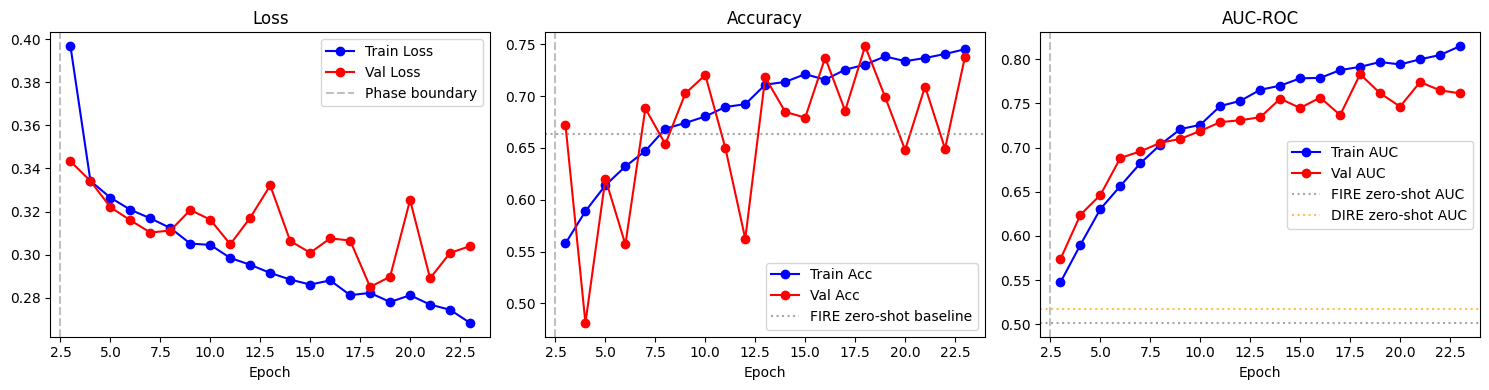

Training curves saved.


In [ ]:
import matplotlib.pyplot as plt

all_history = phase2_history
x = [h['epoch'] + (0 if h['phase'] == 1 else 2) for h in all_history]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(x, [h['train_loss'] for h in all_history], 'b-o', label='Train Loss')
axes[0].plot(x, [h['val_loss']   for h in all_history], 'r-o', label='Val Loss')
axes[0].axvline(x=2.5, color='gray', linestyle='--', alpha=0.5, label='Phase boundary')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(x, [h['train_acc'] for h in all_history], 'b-o', label='Train Acc')
axes[1].plot(x, [h['val_acc']   for h in all_history], 'r-o', label='Val Acc')
axes[1].axhline(y=0.6633, color='gray', linestyle=':', alpha=0.7, label='FIRE zero-shot baseline')
axes[1].axvline(x=2.5, color='gray', linestyle='--', alpha=0.5)
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()

axes[2].plot(x, [h['train_auc'] for h in all_history], 'b-o', label='Train AUC')
axes[2].plot(x, [h['val_auc']   for h in all_history], 'r-o', label='Val AUC')
axes[2].axhline(y=0.5016, color='gray', linestyle=':', alpha=0.7, label='FIRE zero-shot AUC')
axes[2].axhline(y=0.5174, color='orange', linestyle=':', alpha=0.7, label='DIRE zero-shot AUC')
axes[2].axvline(x=2.5, color='gray', linestyle='--', alpha=0.5)
axes[2].set_title('AUC-ROC'); axes[2].set_xlabel('Epoch'); axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Training curves saved.')

## Cell 13 — Final Test Set Evaluation


In [ ]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, classification_report
)
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

model.eval()
all_probs, all_labels = [], []

print('Running inference on test set...')
t0 = time.time()

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.cuda()
        out, *_ = model(imgs)
        probs = torch.sigmoid(out[:, 0]).cpu().tolist()
        all_probs.extend(probs)
        all_labels.extend(labels.tolist())

elapsed = time.time() - t0
print(f'Inference complete in {elapsed:.1f}s  ({len(all_labels)} images)')

y_pred = [1 if p >= 0.5 else 0 for p in all_probs]
acc = accuracy_score(all_labels, y_pred)
auc = roc_auc_score(all_labels, all_probs)
f1  = f1_score(all_labels, y_pred)
cm  = confusion_matrix(all_labels, y_pred)

print('\n' + '=' * 55)
print('  FIRE Fine-Tuned Results (OpenFake test set)')
print('=' * 55)
print(f'  Accuracy : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  AUC      : {auc:.4f}')
print(f'  F1 Score : {f1:.4f}')
print('=' * 55)
print(f'\n  [Reference] FIRE zero-shot : Acc=0.6633  AUC=0.5016  F1=0.7968')
print(f'  [Reference] DIRE zero-shot : Acc=0.6667  AUC=0.5174  F1=0.7997')
print('\nConfusion Matrix (rows=true, cols=pred):')
print(f'               Pred Real  Pred Fake')
print(f'  True Real  :   {cm[0][0]:>5}      {cm[0][1]:>5}')
print(f'  True Fake  :   {cm[1][0]:>5}      {cm[1][1]:>5}')
print('\nFull Classification Report:')
print(classification_report(all_labels, y_pred, target_names=['real', 'fake']))

Running inference on test set...


/content/FIRE/utils/network_utils.py:234: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /pytorch/aten/src/ATen/native/Copy.cpp:308.)
  return middle_freq_image, middle_filtered_image, mask_mid_frq.to(torch.float32), mask_mid_filterd.to(torch.float32)


Inference complete in 193.8s  (900 images)

  FIRE Fine-Tuned Results (OpenFake test set)
  Accuracy : 0.6889  (68.89%)
  AUC      : 0.7320
  F1 Score : 0.7701

  [Reference] FIRE zero-shot : Acc=0.6633  AUC=0.5016  F1=0.7968
  [Reference] DIRE zero-shot : Acc=0.6667  AUC=0.5174  F1=0.7997

Confusion Matrix (rows=true, cols=pred):
               Pred Real  Pred Fake
  True Real  :     151        149
  True Fake  :     131        469

Full Classification Report:
              precision    recall  f1-score   support

        real       0.54      0.50      0.52       300
        fake       0.76      0.78      0.77       600

    accuracy                           0.69       900
   macro avg       0.65      0.64      0.64       900
weighted avg       0.68      0.69      0.69       900



## Cell 14 — Per-Generator Breakdown (SD vs Midjourney)

In [ ]:
import pandas as pd

test_fnames = [os.path.basename(p) for p in test_ds.paths]

results_df = pd.DataFrame({
    'filename' : test_fnames,
    'true'     : all_labels,
    'prob_fake': all_probs,
    'pred'     : y_pred
})

meta = pd.read_csv('/content/dataset/metadata.csv')
meta['filename'] = meta['image_path'].apply(os.path.basename)
results_df = results_df.merge(meta[['filename', 'label', 'model']], on='filename', how='left')

print('=== Per-Generator Performance (Fine-Tuned FIRE) ===')
real_subset = results_df[results_df['label'] == 'real']

for gen_label in ['stable_diffusion', 'midjourney']:
    subset = results_df[results_df['label'] == gen_label]
    if len(subset) == 0:
        continue
    combined = pd.concat([real_subset, subset])
    acc_g = accuracy_score(combined['true'], combined['pred'])
    try:
        auc_g = roc_auc_score(combined['true'], combined['prob_fake'])
    except:
        auc_g = float('nan')
    f1_g = f1_score(combined['true'], combined['pred'], zero_division=0)
    print(f'\n  {gen_label}  (n={len(subset)} fake + {len(real_subset)} real)')
    print(f'    Accuracy : {acc_g:.4f}    AUC : {auc_g:.4f}    F1 : {f1_g:.4f}')

print('\n=== SD Sub-Model Breakdown ===')
sd_subset = results_df[results_df['label'] == 'stable_diffusion']
for model_name, grp in sd_subset.groupby('model'):
    recall = grp['pred'].mean()
    print(f'  {model_name:35s}  n={len(grp):4d}  fake_recall={recall:.3f}')

=== Per-Generator Performance (Fine-Tuned FIRE) ===

  stable_diffusion  (n=296 fake + 300 real)
    Accuracy : 0.6242    AUC : 0.6841    F1 : 0.6637

  midjourney  (n=304 fake + 300 real)
    Accuracy : 0.6606    AUC : 0.7787    F1 : 0.7076

=== SD Sub-Model Breakdown ===
  sd-1.5                               n=  14  fake_recall=0.929
  sd-1.5-dreamshaper                   n=  21  fake_recall=0.905
  sd-1.5-epicdream                     n=   9  fake_recall=0.889
  sd-2.1                               n=  67  fake_recall=0.881
  sd-3.5                               n=  68  fake_recall=0.544
  sdxl                                 n=  25  fake_recall=0.760
  sdxl-epic-realism                    n=  34  fake_recall=0.794
  sdxl-juggernaut                      n=  16  fake_recall=0.688
  sdxl-realvis-v5                      n=  21  fake_recall=0.476
  sdxl-touchofrealism                  n=  21  fake_recall=0.857
